# PINN 2D · Poisson

主线二覆盖二维 Poisson。区域为正方形 $[-1,1]^2$，方程和边界为

$$-u_{xx}-u_{yy}=2\pi^2\sin(\pi x)\sin(\pi y),\qquad u|_{\partial\Omega}=0.$$

解析解 $u=\sin(\pi x)\sin(\pi y)$ 只在训练后比较，不进入 loss。边界是软
Dirichlet 零条件（``DirichletBC(0)``），不使用 hard_boundary。已提交的演示结果为
**5000** 步、相对 L2 约 **0.0337**。下面的固定随机种子、8 步 CPU **smoke**
只检查链路，不是该演示数字。


In [1]:
from pathlib import Path
import json
import math

import torch

import openpinn as op

print("OpenPINN", op.__version__, "| CPU smoke")


OpenPINN 0.2.0 | CPU smoke


## 定义二维 PDE 与边界


In [2]:
domain = op.Polygon([(-1.0, -1.0), (1.0, -1.0), (1.0, 1.0), (-1.0, 1.0)])

def poisson_residual(coordinates, prediction):
    forcing = (
        2.0 * math.pi**2
        * torch.sin(math.pi * coordinates[:, 0:1])
        * torch.sin(math.pi * coordinates[:, 1:2])
    )
    return (
        -op.hessian(prediction, coordinates, i=0, j=0)
        - op.hessian(prediction, coordinates, i=1, j=1)
        - forcing
    )

def exact_u(coordinates):
    return torch.sin(math.pi * coordinates[:, 0:1]) * torch.sin(math.pi * coordinates[:, 1:2])

problem = op.PDEProblem(
    domain,
    poisson_residual,
    [op.DirichletBC(0.0)],
    exact_solution=exact_u,
    name="poisson_2d",
)
print(problem.name, "| domain dim", problem.domain.dim, "| soft DirichletBC(0)")


poisson_2d | domain dim 2 | soft DirichletBC(0)


## 训练：PDE + BC 配点


In [3]:
result = op.solve(
    problem,
    method="baseline",
    steps=8,
    seed=0,
    device="cpu",
    model={"hidden_layers": [16, 16]},
    sampling={"interior": 24, "boundary": 16},
    overrides={"evaluation": {"points": {"x": 9, "y": 9}}},
    output_dir=Path("/tmp/openpinn-m20-pinn-poisson-2d"),
    plot=False,
)
print(json.dumps({key: result.metrics[key] for key in (
    "final_total_loss", "pde_residual_rmse", "relative_l2_error", "boundary_rmse"
)}, indent=2))


step=1 total=1.105292e+02
step=2 total=8.294339e+01
step=3 total=8.993772e+01
step=4 total=1.064116e+02
step=5 total=9.894130e+01
step=6 total=1.284123e+02
step=7 total=8.507335e+01
step=8 total=7.120224e+01
{
  "final_total_loss": 71.20223999023438,
  "pde_residual_rmse": 8.76804256439209,
  "relative_l2_error": 1.0357592105865479,
  "boundary_rmse": 0.1733049750328064
}


## Smoke 指标

固定种子 8 步 CPU **smoke** 只检查调用链路，不是演示数字。损失和误差已打印在上面的训练输出中。本页不再绘制 smoke 损失曲线或场对比。演示图见下一节，文件在 `examples/tutorials/artifacts/m19/poisson_2d_pinn/`。


## 已提交的演示结果

下图来自维护者演示训练，文件在 `examples/tutorials/artifacts/m19/poisson_2d_pinn/`。相对 L2 约 **0.0337**（5000 步，解析参考）。上面的 CPU **smoke** 只检查调用链路。


demo stop_steps=5000 relative_l2_error=0.033739 passed=True


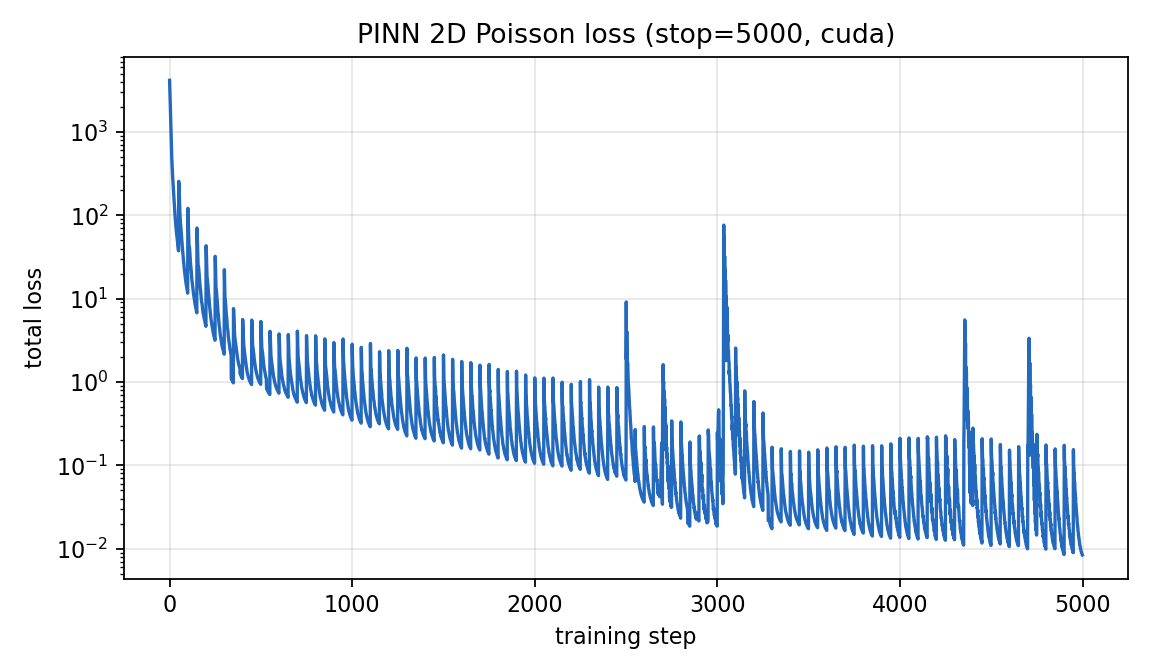

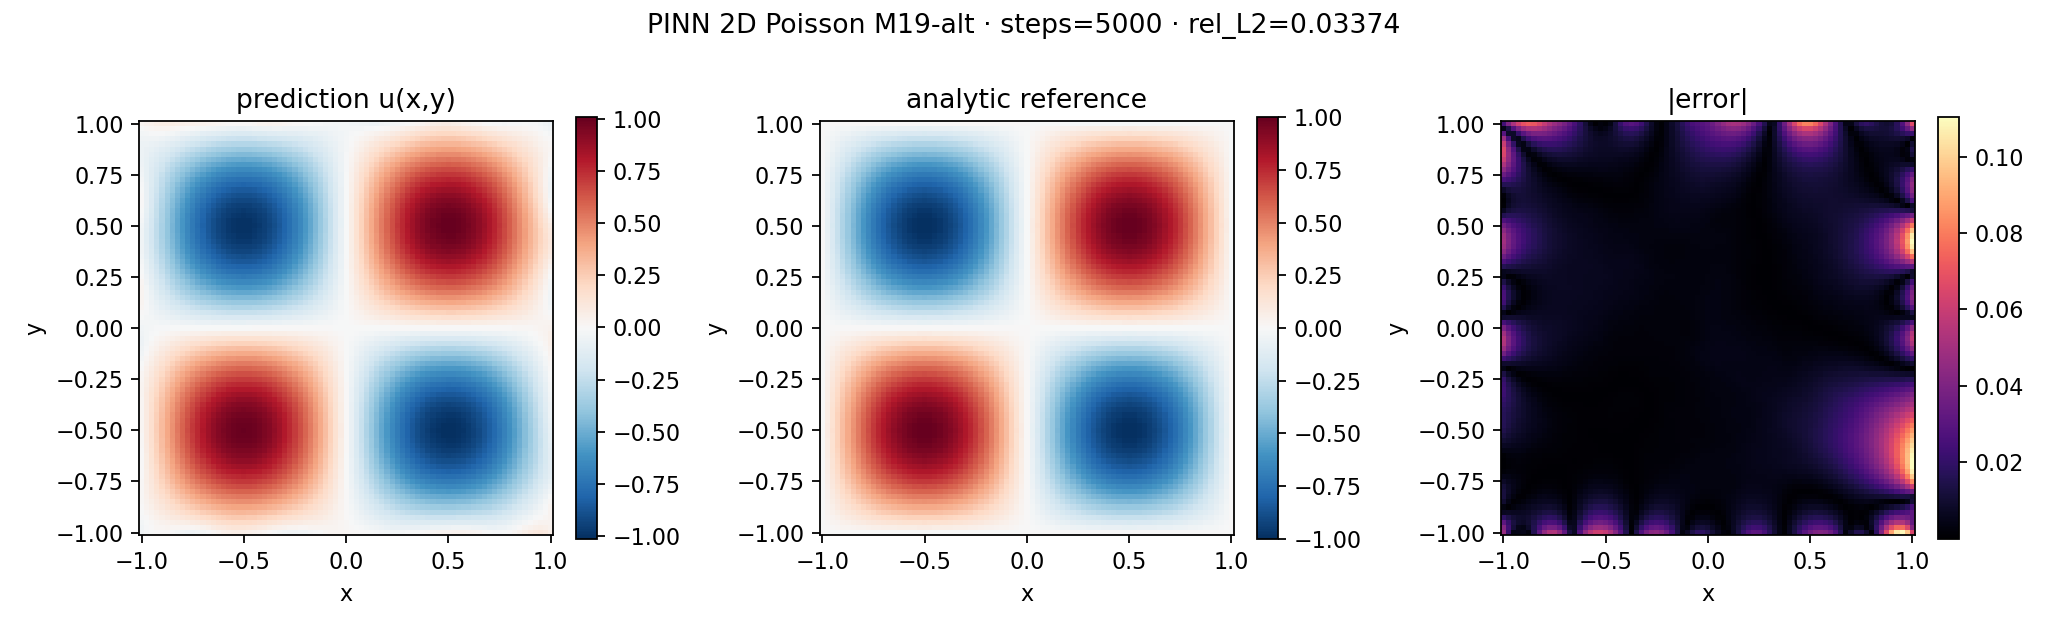

In [1]:
from pathlib import Path
import json
from IPython.display import Image, display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file())
art = ROOT / "examples/tutorials/artifacts/m19/poisson_2d_pinn"
metrics = json.loads((art / "metrics.json").read_text(encoding="utf-8"))
print(
    f"demo stop_steps={metrics['stop_steps']} "
    f"relative_l2_error={metrics['relative_l2_error']:.6f} "
    f"passed={metrics['passed']}"
)
display(Image(filename=str(art / "loss.png")))
display(Image(filename=str(art / "solution_vs_reference.png")))
